In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  

In [ ]:
df.drop_duplicates(inplace=True)

print("Shape after removing duplicates:", df.shape)
print("\nLoan status distribution:")
print(df["loan_status"].value_counts())


Shape after removing duplicates: (32416, 12)

Loan status distribution:
loan_status
0    25327
1     7089
Name: count, dtype: int64


In [5]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (32416, 11)
Target: (32416,)


In [6]:
numerical_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(include="object").columns

print("Numerical columns:", list(numerical_cols))
print("Categorical columns:", list(categorical_cols))

Numerical columns: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical columns: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [7]:
# Fill missing numerical values
X[numerical_cols] = X[numerical_cols].fillna(X[numerical_cols].median())

# Fill missing categorical values
for col in categorical_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

# Encode categorical columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

print("Missing values remaining:", X.isnull().sum().sum())
print("Final feature shape:", X.shape)

X.head()

Missing values remaining: 0
Final feature shape: (32416, 22)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
0,22,59000,123.0,35000,16.02,0.59,3,0,0,1,...,0,1,0,0,0,1,0,0,0,1
1,21,9600,5.0,1000,11.14,0.10,2,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,25,9600,1.0,5500,12.87,0.57,3,0,0,0,...,1,0,0,0,1,0,0,0,0,0
3,23,65500,4.0,35000,15.23,0.53,2,0,0,1,...,1,0,0,0,1,0,0,0,0,0
4,24,54400,8.0,35000,14.27,0.55,4,0,0,1,...,1,0,0,0,1,0,0,0,0,1


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (25932, 22)
Testing shape: (6484, 22)


In [9]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),

    "Naive Bayes": make_pipeline(
        StandardScaler(),
        GaussianNB()
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Decision Tree trained successfully
Naive Bayes trained successfully
SVM trained successfully
KNN trained successfully


In [10]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1 Score", ascending=False)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.9269,0.9453,0.7066,0.8087
2,SVM,0.9105,0.9224,0.6453,0.7593
3,KNN,0.8927,0.8451,0.6234,0.7175
1,Naive Bayes,0.8342,0.6834,0.4506,0.5431


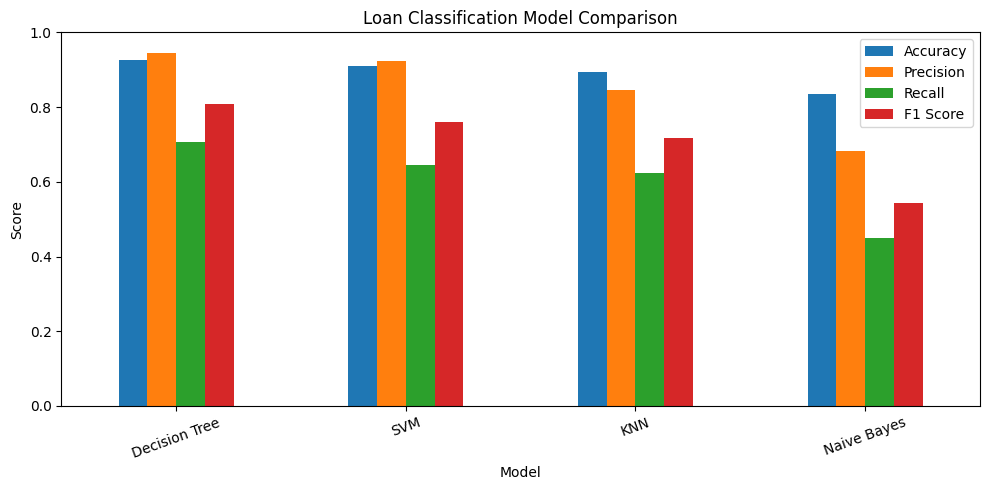

In [11]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Loan Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [12]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    print("\nModel:", name)
    print(classification_report(y_test, y_pred, zero_division=0))


Model: Decision Tree
              precision    recall  f1-score   support

           0       0.92      0.99      0.95      5066
           1       0.95      0.71      0.81      1418

    accuracy                           0.93      6484
   macro avg       0.93      0.85      0.88      6484
weighted avg       0.93      0.93      0.92      6484


Model: Naive Bayes
              precision    recall  f1-score   support

           0       0.86      0.94      0.90      5066
           1       0.68      0.45      0.54      1418

    accuracy                           0.83      6484
   macro avg       0.77      0.70      0.72      6484
weighted avg       0.82      0.83      0.82      6484


Model: SVM
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      5066
           1       0.92      0.65      0.76      1418

    accuracy                           0.91      6484
   macro avg       0.92      0.82      0.85      6484
weighted avg       0

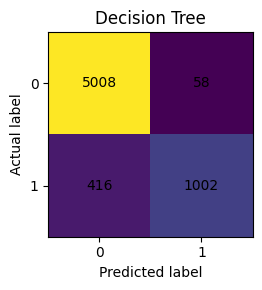

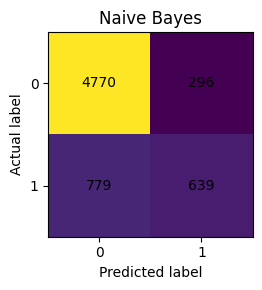

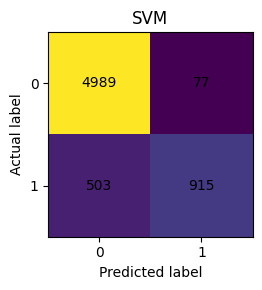

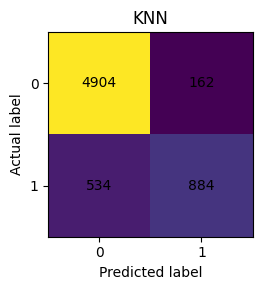

In [13]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    plt.imshow(cm)
    plt.title(name)
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.xticks([0, 1], ["0", "1"])
    plt.yticks([0, 1], ["0", "1"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.tight_layout()
    plt.show()

In [14]:
best_model = results_df.iloc[0]["Model"]

print("Best model based on F1 Score:", best_model)
print(results_df.round(4))

Best model based on F1 Score: Decision Tree
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.9269     0.9453  0.7066    0.8087
2            SVM    0.9105     0.9224  0.6453    0.7593
3            KNN    0.8927     0.8451  0.6234    0.7175
1    Naive Bayes    0.8342     0.6834  0.4506    0.5431
